In [43]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time

In [44]:
filename = "damage_data13.csv"
df = pd.read_csv(filename, header=0, sep=',')
#print('Are ther any Nan value?:\n', np.isnan(df).any())
# ignore rows which contain zero
# ignore_zero = df[(df['Strain']==0) | (df['Stress']==0) | (df['Temp']==0) | (df['Rate']==0)]
#df=pd.concat([df, ignore_zero, ignore_zero]).drop_duplicates(keep=False)
df.head()

,Disp,Force,Geom,D1,D2,D3,D4,Triax,Lode
0,0.950133,8.82907,0,0.1,0.1,0.8,0.1,0.366318,0.892602
1,2.350740,7.69238,0,1.5,0.1,0.8,0.1,0.815011,0.192986
2,2.425730,7.29386,0,2.9,0.1,0.8,0.1,0.000000,0.000000
3,0.675097,8.49918,0,0.1,1.5,0.8,0.1,0.362448,0.902777
4,0.500090,8.19628,0,0.1,2.9,0.8,0.1,0.361502,0.904733


In [45]:
df1 = round(df,6)

## Preprocessing

In [46]:
df.columns

Index(['Disp', 'Force', 'Geom', 'D1', 'D2', 'D3', 'D4', 'Triax', 'Lode'], dtype='object')

In [47]:
df['D2'].max()

2.9

In [48]:
# apply scaling
df_scaled = pd.DataFrame()
disp_range = np.array([0.180007, 2.42573])
force_range = np.array([2.43178, 9.82558])
#s_max_range = np.array([821.064, 2669.76])
#s_mid_range = np.array([53.9087, 1678.56]) 
#s_min_range = np.array([8.36831, 1104.41])
#peeq_range = np.array([0.0656731, 1.92155])
triax_range = np.array([-0.666351, 0.996155])
lode_range = np.array([-0.993733, 0.986])
geom_range = np.array([0,4])
d1_range = np.array([0.1, 2.9])
d2_range = np.array([0.1, 2.9])
d3_range = np.array([0.8, 0.9])
d4_range = np.array([0.1, 2.9])


def manual_scaling(feat, range_value):
    return (feat - range_value[0])/(range_value[1] - range_value[0])
def manual_descaling(feat, range_value): # inverse of the function above
    return (feat * (range_value[1] - range_value[0])) + range_value[0]

#col_ranges = {'Disp': disp_range,
#              'Force': force_range,
#              'S_max': s_max_range,
#              'S_mid': s_mid_range,
#              'S_min': s_min_range,
#              'Peeq': peeq_range,
#              'Triax': triax_range,
#              'Lode': lode_range,
#              'D1': d1_range,
#              'D2': d2_range,
#              'D3': d3_range,
#              'D4': d4_range}

col_ranges = {'Disp': disp_range,
              'Force': force_range,
              'Geom': geom_range,
              'D1': d1_range,
              'D2': d2_range,
              'D3': d3_range,
              'D4': d4_range,
              'Triax': triax_range,
              'Lode': lode_range}

inp_col_ranges = {'Disp': disp_range,
              'Force': force_range,
              'Geom': geom_range }

for column, col_range in col_ranges.items():
    df_scaled[column] = manual_scaling(df[column], col_range)
    
df_scaled.head()

,Disp,Force,Geom,D1,D2,D3,D4,Triax,Lode
0,0.342930,0.865224,0.0,0.0,0.0,0.0,0.0,0.621152,0.952823
1,0.966608,0.711488,0.0,0.5,0.0,0.0,0.0,0.891042,0.599434
2,1.000000,0.657589,0.0,1.0,0.0,0.0,0.0,0.400811,0.501953
3,0.220459,0.820606,0.0,0.0,0.5,0.0,0.0,0.618824,0.957963
4,0.142530,0.779640,0.0,0.0,1.0,0.0,0.0,0.618255,0.958951


In [49]:
df_scaled = round(df_scaled,6)

In [50]:
out_col_ranges = {'D1': d1_range,
              'D2': d2_range,
              'D4': d4_range}

In [51]:
df_scaled

,Disp,Force,Geom,D1,D2,D3,D4,Triax,Lode
0,0.342930,0.865224,0.0,0.0,0.0,0.0,0.0,0.621152,0.952823
1,0.966608,0.711488,0.0,0.5,0.0,0.0,0.0,0.891042,0.599434
2,1.000000,0.657589,0.0,1.0,0.0,0.0,0.0,0.400811,0.501953
3,0.220459,0.820606,0.0,0.0,0.5,0.0,0.0,0.618824,0.957963
4,0.142530,0.779640,0.0,0.0,1.0,0.0,0.0,0.618255,0.958951
...,...,...,...,...,...,...,...,...,...
130,0.550866,0.137389,1.0,0.5,0.5,0.0,1.0,0.400811,0.501953
131,0.539721,0.141573,1.0,1.0,1.0,0.0,1.0,0.000000,0.385297
132,0.309930,0.095357,1.0,0.5,1.0,0.0,1.0,0.317462,0.326233
133,0.707742,0.156589,1.0,1.0,0.5,0.0,1.0,0.400811,0.501953


In [52]:
df_arr = df_scaled
df_arr['Triax'] = df['Triax']
df_arr['Lode'] = df['Lode']
df_arr

,Disp,Force,Geom,D1,D2,D3,D4,Triax,Lode
0,0.342930,0.865224,0.0,0.0,0.0,0.0,0.0,0.366318,0.892602
1,0.966608,0.711488,0.0,0.5,0.0,0.0,0.0,0.815011,0.192986
2,1.000000,0.657589,0.0,1.0,0.0,0.0,0.0,0.000000,0.000000
3,0.220459,0.820606,0.0,0.0,0.5,0.0,0.0,0.362448,0.902777
4,0.142530,0.779640,0.0,0.0,1.0,0.0,0.0,0.361502,0.904733
...,...,...,...,...,...,...,...,...,...
130,0.550866,0.137389,1.0,0.5,0.5,0.0,1.0,0.000000,0.000000
131,0.539721,0.141573,1.0,1.0,1.0,0.0,1.0,-0.666351,-0.230948
132,0.309930,0.095357,1.0,0.5,1.0,0.0,1.0,-0.138569,-0.347878
133,0.707742,0.156589,1.0,1.0,0.5,0.0,1.0,0.000000,0.000000


## Decompose features and labels

In [53]:
#feature_columns = ['Disp', 'Force', 'S_max', 'S_mid', 'S_min', 'Peeq', 'Triax', 'Lode']
feature_columns = ['Disp', 'Force', 'Geom']
label_columns = ['D1', 'D2', 'D4']

df_features = pd.DataFrame()
df_labels = pd.DataFrame()

for col in feature_columns:
    df_features[col] = df_scaled[col]
    
for col in label_columns:
    df_labels[col] = df_scaled[col]

In [54]:
X = df_features.to_numpy()
y = df_labels.to_numpy()

In [55]:
print(X.shape)
print(y.shape)

(135, 3)
(135, 3)


## Decompose train and test set

In [56]:
from sklearn.model_selection import train_test_split

In [57]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=96, test_size=0.1)

In [58]:
print(X_train.shape)
print(X_test.shape)

(121, 3)
(14, 3)


## ANN

In [59]:
from keras.layers import Dense
from keras.models import Sequential
from keras.wrappers.scikit_learn import KerasRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from scipy import stats
from scipy.stats import randint as sp_randint
import tensorflow as tf

In [60]:
# utility function to report best scores
def report(results, n_top=3):
    for i in range(1, n_top + 1):
        candidates = np.flatnonzero(results['rank_test_score'] == i)
        for candidate in candidates:
            print("Model with rank: {0}".format(i))
            print("Mean validation score: {0:.3f} (std: {1:.3f})".format(
                  results['mean_test_score'][candidate],
                  results['std_test_score'][candidate]))
            print("Parameters: {0}".format(results['params'][candidate]))
            print("")

In [61]:
arr = df_scaled.to_numpy()

In [62]:
df_scaled

,Disp,Force,Geom,D1,D2,D3,D4,Triax,Lode
0,0.342930,0.865224,0.0,0.0,0.0,0.0,0.0,0.366318,0.892602
1,0.966608,0.711488,0.0,0.5,0.0,0.0,0.0,0.815011,0.192986
2,1.000000,0.657589,0.0,1.0,0.0,0.0,0.0,0.000000,0.000000
3,0.220459,0.820606,0.0,0.0,0.5,0.0,0.0,0.362448,0.902777
4,0.142530,0.779640,0.0,0.0,1.0,0.0,0.0,0.361502,0.904733
...,...,...,...,...,...,...,...,...,...
130,0.550866,0.137389,1.0,0.5,0.5,0.0,1.0,0.000000,0.000000
131,0.539721,0.141573,1.0,1.0,1.0,0.0,1.0,-0.666351,-0.230948
132,0.309930,0.095357,1.0,0.5,1.0,0.0,1.0,-0.138569,-0.347878
133,0.707742,0.156589,1.0,1.0,0.5,0.0,1.0,0.000000,0.000000


In [63]:
arr[130, 8]

0.0

In [64]:
def create_loss_function(arr):
    def custom_loss(y_true, y_pred):
        
        model_loss = tf.reduce_mean(tf.square(y_true - y_pred))
        
        d1_true = y_true[:,0]
        d2_true = y_true[:,1]
        d4_true = y_true[:,2]

        d1_pred = y_pred[:,0]
        d2_pred = y_pred[:,1]
        d4_pred = y_pred[:,2]
        
        mse_list = []
        
        tf_scaled = tf.constant(arr, dtype=tf.float32)
     
        for i in range(y_true.shape[0]):
            #d1t = manual_descaling(d1_true[i], d1_range)
            #d2t = manual_descaling(d1_true[i], d2_range)
            #d3t = manual_descaling(d1_true[i], d3_range)
            #d4t = manual_descaling(d1_true[i], d4_range)
            d1t = d1_true[i]
            d2t = d1_true[i]
            d4t = d1_true[i]
            
            #d1p = manual_descaling(d1_pred[i], d1_range)
            #d2p = manual_descaling(d1_pred[i], d2_range)
            #d3p = manual_descaling(d1_pred[i], d3_range)
            #d4p = manual_descaling(d1_pred[i], d4_range)
            d1p = d1_pred[i]
            d2p = d1_pred[i]
            d4p = d1_pred[i]
                
            condition = tf.reduce_all(tf.equal(tf_scaled[:, [3,4,6]], [d1_true[i], d2_true[i], d4_true[i]]), axis=1)
            selected_row = tf.boolean_mask(tf_scaled, condition)
            triax = selected_row[:,7]
            lode = selected_row[:,8]
            #print(triax)
            #print(lode)
            peeq_true = (d1t * tf.exp(-d2t*triax) - (0.8*tf.exp(-d4t*triax))) * lode**2 + 0.8*tf.exp(-d4t*triax)    
            peeq_pred = (d1p * tf.exp(-d2p*triax) - (0.8*tf.exp(-d4p*triax))) * lode**2 + 0.8*tf.exp(-d4p*triax) 
            
            ms_err = (peeq_true - peeq_pred)**2
            #print(ms_err)
            mse_list.append(ms_err)
            
        loss = tf.reduce_mean(mse_list)

        return (loss + model_loss)

    return custom_loss


In [65]:
import tensorflow.python.ops.numpy_ops.np_config as np_config

In [66]:
np_config.enable_numpy_behavior()

In [67]:
def ANNmodel(hid_layers=[], in_dim=1, out_dim=3):
    model = Sequential()
    if len(hid_layers) == 0:
        model.add(Dense(out_dim, input_dim=in_dim, activation='relu', kernel_initializer='normal'))
    elif len(hid_layers) == 1:
        model.add(Dense(in_dim, input_dim=in_dim, activation='relu', 
                        kernel_initializer='normal'))
        model.add(Dense(out_dim))
    else:
        model.add(Dense(hid_layers[0], input_dim=in_dim, activation='relu', 
                        kernel_initializer='normal'))
        for layer in hid_layers[1:]:
            model.add(Dense(layer, activation='relu'))
        model.add(Dense(out_dim))
    loss_function = create_loss_function(arr)
    model.compile(loss=loss_function, optimizer='adam', run_eagerly=True)
    return model

def get_hid_layers(min_layers=0, max_layers=5, min_neurons=1, max_neurons=10, n_iter=1):
    hid_layers = []
    for _ in range(n_iter):
        layers = np.random.randint(min_layers, max_layers)
        hid_layers.append(np.random.randint(low=min_neurons, high=max_neurons, size=layers).tolist())
    return hid_layers

In [68]:
#train
runANN = False
np.random.seed(99)
n_iter = 50
param_dist = {'hid_layers': get_hid_layers(max_layers=6, min_neurons=1, 
                                           max_neurons=20, n_iter=n_iter)}

if runANN:
    ann = KerasRegressor(build_fn=ANNmodel, in_dim=X_train.shape[1], 
                         epochs=200, batch_size=16, verbose=0)
    random_search_ann = GridSearchCV(estimator=ann, param_grid=param_dist, 
                                     scoring='neg_mean_squared_error')
    start = time.time()
    random_search_ann.fit(X_train, y_train)
    elapsed_ann = (time.time() - start)
    print("RandomizedSearchCV took %.2f seconds for %d candidates"
          " parameter settings." % (elapsed_ann, n_iter))
    report(random_search_ann.cv_results_)

In [69]:
# test
runANN = False 
if runANN:
    best_ann = random_search_ann.best_estimator_
else:
    best_ann_param =  {'hid_layers': [16, 10, 4, 19, 6]} 
    best_ann = KerasRegressor(build_fn=ANNmodel, in_dim=X.shape[1],
                              epochs=300, batch_size=8, verbose=0, **best_ann_param)
start = time.time()
history=best_ann.fit(X, y)
elapsed_ann_test = (time.time() - start)
print('r2_score for training set:', r2_score(y, best_ann.predict(X)))
print("ANN took %.2f seconds for test." % (elapsed_ann_test))

r2_score for training set: 0.2513980951014918
ANN took 279.35 seconds for test.


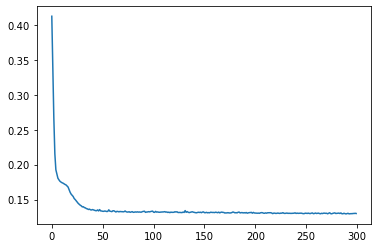

In [70]:
plt.plot(history.history['loss'])

### Predicting Optimal Parameter Sets

In [71]:
inp = np.array([[2.27355, 8.0538, 1], [1.6914, 8.345219, 2], [1.37666, 8.690144, 3], [1.27861, 9.25452, 4], [2.01798, 3.113823, 5]])

In [72]:
inp_df = pd.DataFrame(inp)
inp_df.columns = ['Disp', 'Force', 'Geom']
inp_df

,Disp,Force,Geom
0,2.27355,8.053800,1.0
1,1.69140,8.345219,2.0
2,1.37666,8.690144,3.0
3,1.27861,9.254520,4.0
4,2.01798,3.113823,5.0


In [73]:
inp_df_scaled = pd.DataFrame()
for column, col_range in inp_col_ranges.items():
    inp_df_scaled[column] = manual_scaling(inp_df[column], col_range)

In [74]:
inp_df_scaled

,Disp,Force,Geom
0,0.932236,0.760369,0.25
1,0.673010,0.799783,0.50
2,0.532859,0.846434,0.75
3,0.489198,0.922765,1.00
4,0.818433,0.092245,1.25


In [75]:
inp_scaled = np.array(inp_df_scaled)

In [76]:
best_ann.predict(inp_scaled)

array([[0.85711074, 0.4044978 , 0.39081573],
       [0.88505334, 0.44048175, 0.42443097],
       [0.7697864 , 0.484884  , 0.47211963],
       [0.80569607, 0.49980634, 0.48505545],
       [0.7430237 , 0.3674307 , 0.35967588]], dtype=float32)

In [77]:
ann_pred_scaled = pd.DataFrame(best_ann.predict(inp_scaled))
ann_pred_scaled.columns = ['D1', 'D2', 'D4']
pred = pd.DataFrame()
for column, col_range in out_col_ranges.items():
    pred[column] = manual_descaling(ann_pred_scaled[column], col_range)

In [78]:
pred

,D1,D2,D4
0,2.499910,1.232594,1.194284
1,2.578149,1.333349,1.288407
2,2.255402,1.457675,1.421935
3,2.355949,1.499458,1.458155
4,2.180466,1.128806,1.107092


### Plotting fracture loci

In [79]:
peeq_points = [0.821925, 0.805, 0.782969, 0.982276, 0.747469]
triax_points = [0.735486, 0.763, 0.775465, 0.421326, 0.154543]
lode_points = [0.271787, 0.187, 0.14384, 0.968038, 0.165233]

### G0

In [80]:
# G0
d1, d2, d3, d4 = pred['D1'].iloc[0], pred['D2'].iloc[0], 0.8, pred['D4'].iloc[0]

In [81]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

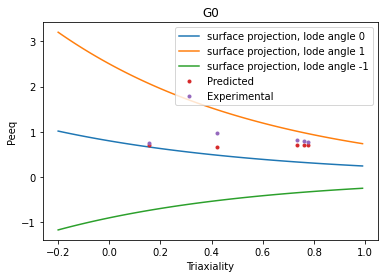

In [82]:
triax = np.arange(-0.2, 1, 0.01)
lode = 0
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * lode**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.title('G0')
plt.legend()

In [83]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

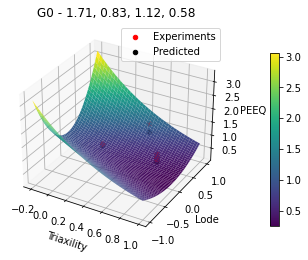

In [84]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experiments')
ax.scatter(triax_points, lode_points, z_predicted, color='black', alpha=1.0, label='Predicted')

ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G0 - 1.71, 0.83, 1.12, 0.58')
ax.legend()

### G1

In [85]:
# G1
d1, d2, d3, d4 = pred['D1'].iloc[1], pred['D2'].iloc[1], 0.8, pred['D4'].iloc[1]

In [86]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

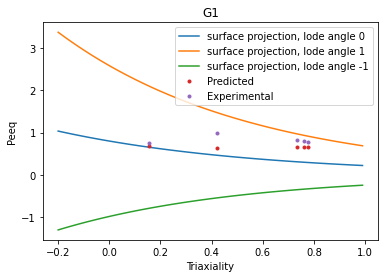

In [87]:
triax = np.arange(-0.2, 1, 0.01)
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 0**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.title('G1')
plt.legend()

In [88]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

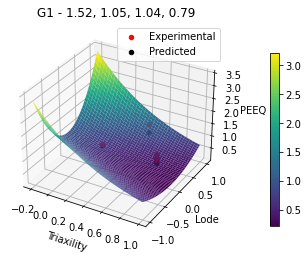

In [89]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experimental')
ax.scatter(triax_points, lode_points, z_predicted, color='black', alpha=1.0, label='Predicted')

ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G1 - 1.52, 1.05, 1.04, 0.79')
ax.legend()

### G2

In [90]:
d1, d2, d3, d4 = pred['D1'].iloc[2], pred['D2'].iloc[2], 0.8, pred['D4'].iloc[2]

In [91]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

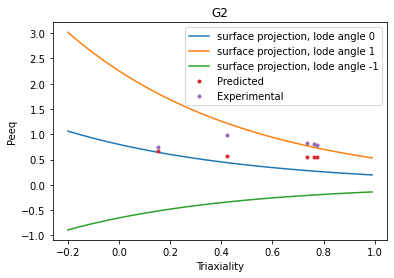

In [92]:
triax = np.arange(-0.2, 1, 0.01)
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 0**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.title('G2')
plt.legend()

In [93]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

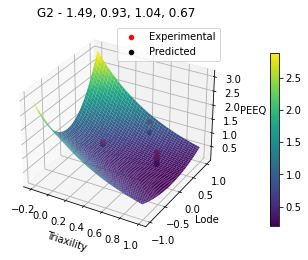

In [94]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experimental')
ax.scatter(triax_points, lode_points, z_predicted, color='black', alpha=1.0, label='Predicted')


ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G2 - 1.49, 0.93, 1.04, 0.67')
ax.legend()

### G3

In [95]:
d1, d2, d3, d4 = pred['D1'].iloc[3], pred['D2'].iloc[3], 0.8, pred['D4'].iloc[3]

In [96]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

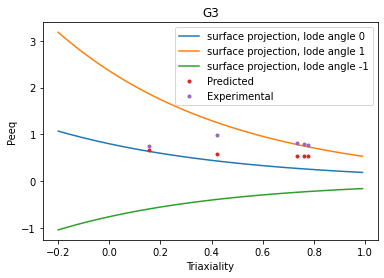

In [97]:
triax = np.arange(-0.2, 1, 0.01)
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 0**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.title('G3')
plt.legend()

In [98]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

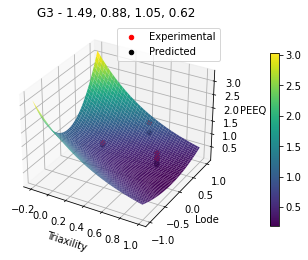

In [99]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experimental')
ax.scatter(triax_points, lode_points, z_predicted, color='black', alpha=1.0, label='Predicted')

ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G3 - 1.49, 0.88, 1.05, 0.62')
ax.legend()

### G4

In [100]:
d1, d2, d3, d4 = pred['D1'].iloc[4], pred['D2'].iloc[4], 0.8, pred['D4'].iloc[4]

In [101]:
x_value = triax_points
y_value = lode_points
z_expected = peeq_points
z_predicted = []
for i in range(5):
    x = triax_points[i]
    y = triax_points[i]
    z = (d1 * np.exp(-d2*x) - (d3*np.exp(-d4*x))) * y**2 + d3*np.exp(-d4*x)
    z_predicted.append(z)

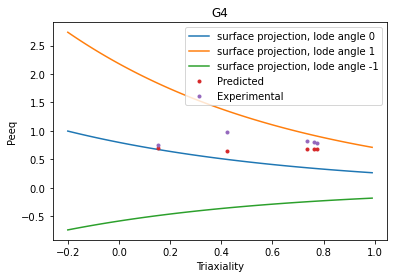

In [102]:
triax = np.arange(-0.2, 1, 0.01)
peeq1 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 0**2 + d3*np.exp(-d4*triax)
peeq2 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * 1**2 + d3*np.exp(-d4*triax)
peeq3 = (d1 * np.exp(-d2*triax) - (d3*np.exp(-d4*triax))) * -1**2 + d3*np.exp(-d4*triax)
plt.plot(triax, peeq1, label='surface projection, lode angle 0')
plt.plot(triax, peeq2, label='surface projection, lode angle 1')
plt.plot(triax, peeq3, label='surface projection, lode angle -1')
plt.plot(triax_points, z_predicted, '.', label='Predicted')
plt.plot(triax_points, peeq_points, '.', label='Experimental')
plt.xlabel('Triaxiality')
plt.ylabel('Peeq')
plt.title('G4')
plt.legend()

In [103]:
lode = np.arange(1,-1, -0.01)
triax = np.arange(-0.2, 1, 0.01)
lode1, triax1 = np.meshgrid(lode, triax)
peeq1 = (d1 * np.exp(-d2*triax1) - (d3*np.exp(-d4*triax1))) * lode1**2 + d3*np.exp(-d4*triax1)

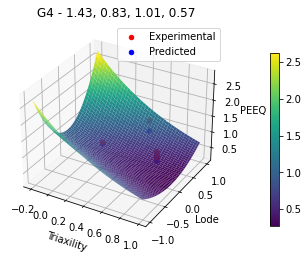

In [104]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Create a color-coded surface plot
surf = ax.plot_surface(triax1, lode1, peeq1, cmap='viridis')

# Add a color bar
cbar = fig.colorbar(surf)
cbar.ax.set_position([0.85, 0.1, 0.02, 0.75])

ax.scatter(triax_points, lode_points, peeq_points, color='red', alpha=1.0, label='Experimental')
ax.scatter(triax_points, lode_points, z_predicted, color='blue', alpha=1.0, label='Predicted')

ax.set_xlabel('Triaxility')
ax.set_ylabel('Lode')
ax.set_zlabel('PEEQ')
ax.set_title('G4 - 1.43, 0.83, 1.01, 0.57')
ax.legend()